In [2]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error

# 1. Locate the correct petrol prices comparison dataset
dataset_dir = '/root/.cache/kagglehub/datasets/zkskhurram/global-petrol-prices-impact-of-2026-us-iran-war/versions/2'
file_path = os.path.join(dataset_dir, 'petrol_prices_comparison.csv')

# Replace the file loading section with:
file_path = 'petrol_prices_comparison.csv'
# Fallback in case the name is slightly different
if not os.path.exists(file_path):
    csv_files = [f for f in os.listdir('.') if f.endswith('.csv')]
    if not csv_files:
        raise FileNotFoundError("Please put petrol_prices_comparison.csv in this folder.")
    file_path = csv_files[0]

df = pd.read_csv(file_path)
print(f"\nLoaded {os.path.basename(file_path)} successfully. Shape: {df.shape}")

# 2. Automatically find numerical columns and set target
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if not numeric_cols:
    raise ValueError("No numerical columns found in the dataset for regression.")

target_col = numeric_cols[-1]
print(f"Target column selected for regression: {target_col}")

X = df.drop(columns=[target_col])
y = df[target_col]

# Convert non-numeric features using label encoding
for col in X.columns:
    if X[col].dtype == 'object':
        X[col] = LabelEncoder().fit_transform(X[col].astype(str))

X = X.fillna(X.mean())
y = y.fillna(y.mean())

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train and compare models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

best_model_name = None
best_r2 = -float('inf')
results = {}

print("\n--- Model Evaluation ---")
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    r2 = r2_score(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    results[name] = {"R2": r2, "MSE": mse}
    print(f"{name} -> R2 Score: {r2:.4f}, MSE: {mse:.4f}")

    if r2 > best_r2:
        best_r2 = r2
        best_model_name = name

print(f"\nRecommendation: Based on the R2 score, the recommended model is **{best_model_name}** with an R2 of {best_r2:.4f}.")


Loaded petrol_prices_comparison.csv successfully. Shape: (14, 16)
Target column selected for regression: Pct_Since_War

--- Model Evaluation ---
Linear Regression -> R2 Score: -66.5961, MSE: 26305.7802
Random Forest -> R2 Score: -0.7834, MSE: 694.0224
Gradient Boosting -> R2 Score: -0.2682, MSE: 493.5348

Recommendation: Based on the R2 score, the recommended model is **Gradient Boosting** with an R2 of -0.2682.


In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load the specific petrol price comparison dataset
dataset_dir = '/root/.cache/kagglehub/datasets/zkskhurram/global-petrol-prices-impact-of-2026-us-iran-war/versions/2'
file_name = 'petrol_prices_comparison.csv'
file_path = os.path.join(dataset_dir, file_name)

if not os.path.exists(file_path):
    # Fallback to any other numerical price CSV if missing
    csv_files = [f for f in os.listdir(dataset_dir) if 'price' in f.lower() or 'oil' in f.lower()]
    file_path = os.path.join(dataset_dir, csv_files[0])

df = pd.read_csv(file_path)
print(f"Dataset loaded: {os.path.basename(file_path)} ({df.shape[0]} rows, {df.shape[1]} columns)\n")
print(df.head())

# 2. Automatically find numerical columns and set target
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if not numeric_cols:
    raise ValueError("No numerical columns found in the dataset for regression.")

# Set the target as the last numeric column (often the price/value)
target_col = numeric_cols[-1]
print(f"\nTarget variable selected: {target_col}")

X = df.drop(columns=[target_col])
y = df[target_col]

# 3. Preprocess features
for col in X.columns:
    if X[col].dtype == 'object':
        X[col] = LabelEncoder().fit_transform(X[col].astype(str))

X = X.fillna(X.mean())
y = y.fillna(y.mean())

# Split into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train Linear Regression Model First
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict and evaluate
y_pred = lr_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("\n--- Linear Regression Performance ---")
print(f"R2 Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

Dataset loaded: petrol_prices_comparison.csv (14 rows, 16 columns)

       Country  ISO      Region Currency  Before_War_Price  Mar7_Price  \
0     Pakistan  PAK  South Asia      PKR            258.06      321.17   
1        India  IND  South Asia      INR            101.22      101.20   
2   Bangladesh  BGD  South Asia      BDT            120.00      120.00   
3  Afghanistan  AFG  South Asia      AFN             55.00       57.00   
4        Nepal  NPL  South Asia      NPR            157.00      190.00   

   Apr6_Price  Jul13_Price   Unit  Before_War_USD  Mar7_USD  Apr6_USD  \
0      378.41        425.5  PKR/L            0.93      1.15      1.36   
1      101.12        112.4  INR/L            1.09      1.09      1.09   
2      120.00        145.0  BDT/L            0.97      0.97      0.97   
3       61.00         78.0  AFN/L            0.80      0.82      0.95   
4      202.00        245.0  NPR/L            1.06      1.28      1.36   

   Jul13_USD Oil_Import_Dep  Pct_Since_War     T

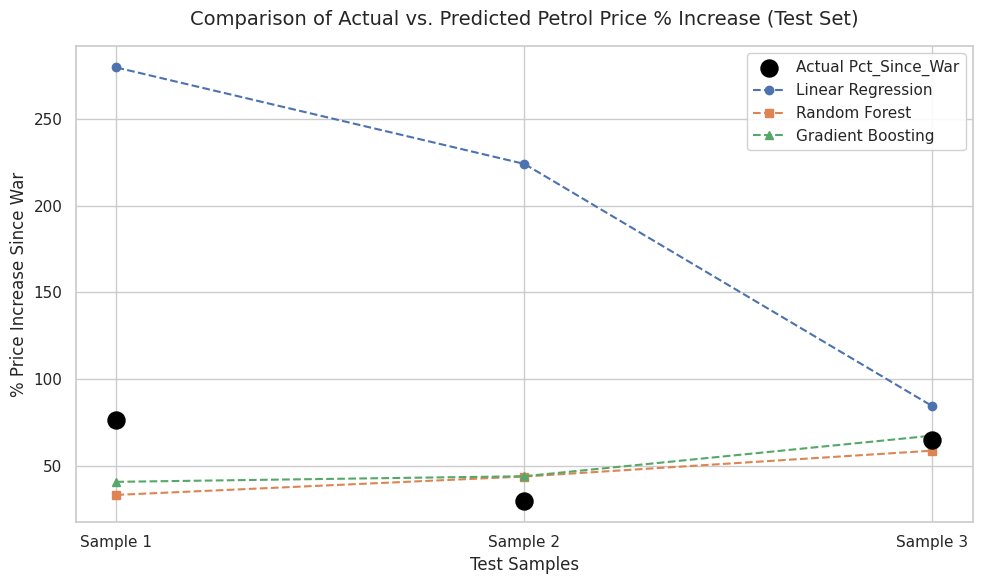

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get predictions from all trained models on the test set
lr_preds = lr_model.predict(X_test)
rf_preds = models['Random Forest'].predict(X_test)
gb_preds = models['Gradient Boosting'].predict(X_test)

# Set up plot styling
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# X-axis indices for the test samples
x_indices = np.arange(len(y_test))

# Plot actual values
plt.scatter(x_indices, y_test.values, color='black', s=150, zorder=5, label='Actual Pct_Since_War')

# Plot predicted values for each model
plt.plot(x_indices, lr_preds, marker='o', linestyle='--', linewidth=1.5, label='Linear Regression')
plt.plot(x_indices, rf_preds, marker='s', linestyle='--', linewidth=1.5, label='Random Forest')
plt.plot(x_indices, gb_preds, marker='^', linestyle='--', linewidth=1.5, label='Gradient Boosting')

# Configure labels, title, and legend
plt.xticks(x_indices, [f"Sample {i+1}" for i in range(len(y_test))])
plt.title("Comparison of Actual vs. Predicted Petrol Price % Increase (Test Set)", fontsize=14, pad=15)
plt.xlabel("Test Samples", fontsize=12)
plt.ylabel("% Price Increase Since War", fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()

plt.show()

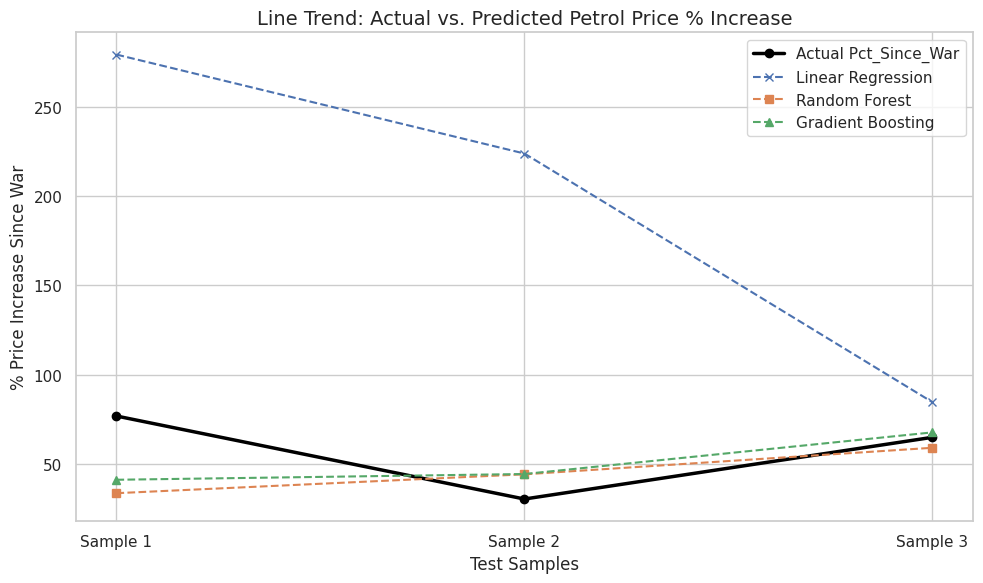

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

x_indices = np.arange(len(y_test))

# Line plot representing actual values and model predictions
plt.plot(x_indices, y_test.values, marker='o', label='Actual Pct_Since_War', color='black', linewidth=2.5)
plt.plot(x_indices, lr_preds, marker='x', label='Linear Regression', linestyle='--')
plt.plot(x_indices, rf_preds, marker='s', label='Random Forest', linestyle='--')
plt.plot(x_indices, gb_preds, marker='^', label='Gradient Boosting', linestyle='--')

plt.xticks(x_indices, [f"Sample {i+1}" for i in range(len(y_test))])
plt.title("Line Trend: Actual vs. Predicted Petrol Price % Increase", fontsize=14)
plt.xlabel("Test Samples", fontsize=12)
plt.ylabel("% Price Increase Since War", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()